Baixar o arquivo de dados.

In [ ]:
import pandas as pd

df = pd.read_csv("delivery_pedidos.csv")

print(df.head())
print(df.shape)
print(df.info())

   pedido_id         data_hora     cidade     bairro restaurante_id  \
0     500000  2024-01-01 11:21  São Paulo    Tatuapé           R912   
1     500001  2024-01-01 20:09  São Paulo    Tatuapé           R760   
2     500002  2024-01-01 11:20  São Paulo    Santana           R760   
3     500003  2024-01-01 22:14  São Paulo      Moema           R338   
4     500004  2024-01-01 12:50  São Paulo  Pinheiros           R169   

  tipo_cozinha plataforma    forma_pagamento cupom  cliente_novo  chuva  \
0   Hambúrguer    Android                Pix   Não         False  False   
1   Hambúrguer    Android                Pix   Sim         False  False   
2   Hambúrguer    Android     cartao credito   Não         False  False   
3     Saudável    Android  Cartão de crédito   Sim          True  False   
4   Hambúrguer    Android                Pix   Não         False  False   

   distancia_km  tempo_entrega_min valor_pedido  taxa_entrega  avaliacao  \
0          2.68                 28     R$ 44,0

Será realizada uma Auditoria no arquivo

In [1]:
# Dimensões
print("Dimensões:", df.shape)

# Duplicatas
print("Linhas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["pedido_id"].duplicated().sum())

# Valores ausentes
print("\n--- VALORES AUSENTES ---")
print(df.isna().sum().sort_values(ascending=False))

# Valores únicos
print("\n--- VALORES ÚNICOS ---")
print(df.nunique().sort_values())

# Tipos
print("\n--- TIPOS ---")
print(df.dtypes)

NameError: name 'df' is not defined

Adicione uma etapa de saneamento antes de calcular as médias operacionais e correlações:

In [ ]:
# 1. Auditar os registos anómalos de tempo e distância
print("Tempos negativos ou zero:", len(df[df["tempo_entrega_min"] <= 0]))
print("Tempos extremos (> 180 min):", len(df[df["tempo_entrega_min"] > 180]))
print("Distâncias extremas (> 30 km):", len(df[df["distancia_km"] > 30]))

# 2. Criar colunas limpas (substituindo erros por NaN para não distorcer médias)
import numpy as np

df["tempo_entrega_limpo"] = df["tempo_entrega_min"].where(
    (df["tempo_entrega_min"] > 0) & (df["tempo_entrega_min"] < 180), np.nan
)

df["distancia_km_limpa"] = df["distancia_km"].where(
    (df["distancia_km"] > 0) & (df["distancia_km"] <= 30), np.nan
)

# 3. Recalcular a correlação com os dados limpos
print(df[["distancia_km_limpa", "tempo_entrega_limpo"]].corr())

Tempos negativos ou zero: 8
Tempos extremos (> 180 min): 25
Distâncias extremas (> 30 km): 7
                     distancia_km_limpa  tempo_entrega_limpo
distancia_km_limpa             1.000000             0.703808
tempo_entrega_limpo            0.703808             1.000000


Investigar as variáveis categóricas:

In [ ]:
colunas_categoricas = [
    "cidade",
    "bairro",
    "tipo_cozinha",
    "plataforma",
    "forma_pagamento",
    "cupom",
    "pais",
    "moeda"
]

for coluna in colunas_categoricas:
    print(f"\n--- {coluna.upper()} ---")
    print(df[coluna].value_counts(dropna=False))


--- CIDADE ---
cidade
São Paulo         3579
Rio de Janeiro    2064
Belo Horizonte    1418
SÃO PAULO          124
SP                 123
São Paulo          115
sao paulo          114
rio de janeiro     103
RJ                 103
Rio                101
BH                  79
belo horizonte      72
B. Horizonte        63
Name: count, dtype: int64

--- BAIRRO ---
bairro
Tatuapé            705
Moema              693
Santana            673
Itaim Bibi         672
Vila Mariana       658
Pinheiros          654
Copacabana         481
Barra da Tijuca    477
Tijuca             477
Méier              472
Botafogo           464
Lourdes            425
Pampulha           414
Savassi            400
Buritis            393
Name: count, dtype: int64

--- TIPO_COZINHA ---
tipo_cozinha
Hambúrguer    1921
Pizza         1786
Brasileira    1561
Japonesa      1116
Saudável       860
Doces          814
Name: count, dtype: int64

--- PLATAFORMA ---
plataforma
Android    4449
iOS        2574
Web         882
NaN 

Investigar as variáveis numéricas:

In [ ]:
df.describe()

,pedido_id,distancia_km,tempo_entrega_min,taxa_entrega,avaliacao,tempo_entrega_limpo,distancia_km_limpa,valor_pedido_limpo
count,8058.000000,7743.000000,8058.000000,8058.000000,6716.000000,8025.000000,7736.000000,8058.000000
mean,504028.500000,3.797731,38.848349,7.268727,4.348868,35.914268,3.537795,71.554325
std,2326.288568,9.409026,54.728561,3.285336,0.685299,11.103244,2.389663,60.264961
min,500000.000000,0.080000,-33.000000,0.000000,1.000000,2.000000,0.080000,11.030000
25%,502014.250000,1.770000,28.000000,6.160000,4.000000,28.000000,1.770000,45.220000
50%,504028.500000,3.030000,35.000000,7.420000,4.000000,35.000000,3.025000,61.610000
75%,506042.750000,4.770000,43.000000,9.077500,5.000000,43.000000,4.760000,85.120000
max,508057.000000,399.650000,999.000000,26.940000,5.000000,105.000000,24.390000,2299.100000


In [ ]:
# 1. Auditar os registos anómalos de tempo e distância
print("Tempos negativos ou zero:", len(df[df["tempo_entrega_min"] <= 0]))
print("Tempos extremos (> 180 min):", len(df[df["tempo_entrega_min"] > 180]))
print("Distâncias extremas (> 30 km):", len(df[df["distancia_km"] > 30]))

# 2. Criar colunas limpas (substituindo erros por NaN para não distorcer médias)
import numpy as np

df["tempo_entrega_limpo"] = df["tempo_entrega_min"].where(
    (df["tempo_entrega_min"] > 0) & (df["tempo_entrega_min"] < 180), np.nan
)

df["distancia_km_limpa"] = df["distancia_km"].where(
    (df["distancia_km"] > 0) & (df["distancia_km"] <= 30), np.nan
)

# 3. Recalcular a correlação com os dados limpos
print(df[["distancia_km_limpa", "tempo_entrega_limpo"]].corr())

Tempos negativos ou zero: 8
Tempos extremos (> 180 min): 25
Distâncias extremas (> 30 km): 7
                     distancia_km_limpa  tempo_entrega_limpo
distancia_km_limpa             1.000000             0.703808
tempo_entrega_limpo            0.703808             1.000000


In [ ]:
df["valor_pedido"].head(30)

0     R$ 44,02
1        45.54
2        92.28
3        39.09
4         74.2
5        69.34
6         50.1
7        54.32
8        79.41
9        48.77
10       18.99
11       92.19
12       44.47
13       72.89
14       25.93
15      209.32
16       52.22
17       57.85
18    R$ 36,08
19       135.3
20       99.65
21       60.46
22       78.54
23       64.54
24        50.7
25       50.04
26       30.21
27      120.21
28    R$ 35,49
29      114.53
Name: valor_pedido, dtype: str

In [ ]:
df["valor_pedido"].tail(30)

8028        34.08
8029        45.14
8030        77.87
8031        40.23
8032        82.21
8033    R$ 235,44
8034       154.13
8035        74.63
8036        75.95
8037        53.47
8038         71.4
8039         75.9
8040        56.99
8041       175.94
8042        33.61
8043        54.13
8044         46.8
8045        80.37
8046        96.31
8047        40.74
8048        75.73
8049        35.96
8050        72.91
8051        53.26
8052        37.94
8053        59.67
8054       164.35
8055       100.11
8056        52.68
8057     R$ 54,69
Name: valor_pedido, dtype: str

In [ ]:
df["valor_pedido"].tail(30)

8028        34.08
8029        45.14
8030        77.87
8031        40.23
8032        82.21
8033    R$ 235,44
8034       154.13
8035        74.63
8036        75.95
8037        53.47
8038         71.4
8039         75.9
8040        56.99
8041       175.94
8042        33.61
8043        54.13
8044         46.8
8045        80.37
8046        96.31
8047        40.74
8048        75.73
8049        35.96
8050        72.91
8051        53.26
8052        37.94
8053        59.67
8054       164.35
8055       100.11
8056        52.68
8057     R$ 54,69
Name: valor_pedido, dtype: str

Criar uma coluna limpa sem destruir a original:

In [ ]:
df["valor_pedido_limpo"] = (
    df["valor_pedido"]
    .str.replace("R$", "", regex=False)
    .str.strip()
    .str.replace(",", ".", regex=False)
)

df["valor_pedido_limpo"] = pd.to_numeric(
    df["valor_pedido_limpo"],
    errors="coerce"
)

Conferindo:

In [ ]:
df[["valor_pedido", "valor_pedido_limpo"]].head(30)

,valor_pedido,valor_pedido_limpo
0,"R$ 44,02",44.02
1,45.54,45.54
2,92.28,92.28
3,39.09,39.09
4,74.2,74.20
5,69.34,69.34
6,50.1,50.10
7,54.32,54.32
8,79.41,79.41
9,48.77,48.77


In [ ]:
df["valor_pedido_limpo"].dtype

dtype('float64')

Verificando se os valores foram limpos.

In [ ]:
df["valor_pedido_limpo"].isna().sum()

np.int64(0)

Fazendo contagem, média, desvio padrão, mínimo, quartis e máximo.

In [ ]:
df["valor_pedido_limpo"].describe()

count    8058.000000
mean       71.554325
std        60.264961
min        11.030000
25%        45.220000
50%        61.610000
75%        85.120000
max      2299.100000
Name: valor_pedido_limpo, dtype: float64

Esse resultado mostra um ponto importante na distribuição do valor dos pedidos:
•	8.058 pedidos válidos
•	Média: R$ 71,55
•	Mediana: R$ 61,61
•	25%: até R$ 45,22
•	75%: até R$ 85,12
•	Mínimo: R$ 11,03
•	Máximo: R$ 2.299,10
•	Desvio padrão: R$ 60,26
O máximo de R$ 2.299,10 chama bastante atenção em comparação à mediana de R$ 61,61. Vale investigar se existem outliers antes de concluir algo sobre gasto dos clientes.


C:\Users\ivane\AppData\Local\Temp\ipykernel_8172\2083661342.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


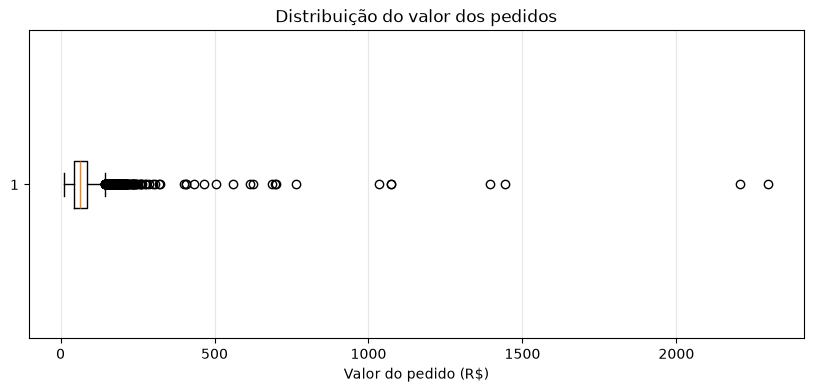

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.boxplot(
    df["valor_pedido_limpo"],
    vert=False
)

plt.title("Distribuição do valor dos pedidos")
plt.xlabel("Valor do pedido (R$)")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [ ]:
df[
    ["pedido_id", "cidade", "valor_pedido_limpo"]
].sort_values(
    "valor_pedido_limpo",
    ascending=False
).head(10)

,pedido_id,cidade,valor_pedido_limpo
6904,506904,Rio,2299.10
3553,503553,São Paulo,2207.79
4023,504023,São Paulo,1441.97
1035,501035,São Paulo,1394.73
5238,505238,Rio de Janeiro,1074.23
6787,506787,Rio de Janeiro,1071.77
491,500491,São Paulo,1035.26
4542,504542,Belo Horizonte,765.04
1736,501736,Rio de Janeiro,700.91
4286,504286,Belo Horizonte,697.91


Entendendo o valor R$ 2.299,10

In [ ]:
# Quartis
Q1 = df["valor_pedido_limpo"].quantile(0.25)
Q3 = df["valor_pedido_limpo"].quantile(0.75)

# Intervalo interquartil
IQR = Q3 - Q1

# Limites pelo critério de 1,5 x IQR
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: R$ {Q1:.2f}")
print(f"Q3: R$ {Q3:.2f}")
print(f"IQR: R$ {IQR:.2f}")
print(f"Limite inferior: R$ {limite_inferior:.2f}")
print(f"Limite superior: R$ {limite_superior:.2f}")

Q1: R$ 45.22
Q3: R$ 85.12
IQR: R$ 39.90
Limite inferior: R$ -14.63
Limite superior: R$ 144.97


In [ ]:
outliers = df[
    (df["valor_pedido_limpo"] < limite_inferior) |
    (df["valor_pedido_limpo"] > limite_superior)
]

print("Quantidade de outliers:", len(outliers))
print("Percentual:", round(len(outliers) / len(df) * 100, 2), "%")


Quantidade de outliers: 352
Percentual: 4.37 %


In [ ]:
outliers[
    ["pedido_id", "cidade", "valor_pedido_limpo"]
].sort_values(
    "valor_pedido_limpo",
    ascending=False
).head(20)

,pedido_id,cidade,valor_pedido_limpo
6904,506904,Rio,2299.10
3553,503553,São Paulo,2207.79
4023,504023,São Paulo,1441.97
1035,501035,São Paulo,1394.73
5238,505238,Rio de Janeiro,1074.23
6787,506787,Rio de Janeiro,1071.77
491,500491,São Paulo,1035.26
4542,504542,Belo Horizonte,765.04
1736,501736,Rio de Janeiro,700.91
4286,504286,Belo Horizonte,697.91


In [ ]:
print("Média com outliers:",
      df["valor_pedido_limpo"].mean())

print("Mediana com outliers:",
      df["valor_pedido_limpo"].median())

print("Média sem outliers:",
      df.loc[
          df["valor_pedido_limpo"] <= limite_superior,
          "valor_pedido_limpo"
      ].mean())

Média com outliers: 71.55432489451476
Mediana com outliers: 61.61
Média sem outliers: 64.92914482221646


Foram identificados valores atípicos pelo método do intervalo interquartil (IQR). Esses registros não foram removidos, pois valores estatisticamente atípicos podem representar pedidos legítimos. A análise dos resultados será realizada com e sem esses valores para avaliar seu impacto nas métricas de gasto.


Verificando valores anormais.

In [ ]:
df["valor_pedido_limpo"].describe()

count    8058.000000
mean       71.554325
std        60.264961
min        11.030000
25%        45.220000
50%        61.610000
75%        85.120000
max      2299.100000
Name: valor_pedido_limpo, dtype: float64

In [ ]:
tratando a data

SyntaxError: invalid syntax (3509878559.py, line 1)

In [ ]:
df["data_hora"] = pd.to_datetime(
    df["data_hora"],
    errors="coerce"
)

print(df["data_hora"].dtype)
print("Datas inválidas:", df["data_hora"].isna().sum())

datetime64[us]
Datas inválidas: 0


In [ ]:
df["hora"] = df["data_hora"].dt.hour
df["mes"] = df["data_hora"].dt.month
df["dia_semana"] = df["data_hora"].dt.day_name()

df[["data_hora", "hora", "mes", "dia_semana"]].head()

,data_hora,hora,mes,dia_semana
0,2024-01-01 11:21:00,11,1,Monday
1,2024-01-01 20:09:00,20,1,Monday
2,2024-01-01 11:20:00,11,1,Monday
3,2024-01-01 22:14:00,22,1,Monday
4,2024-01-01 12:50:00,12,1,Monday


Vou ver os pedidos por hora.

In [ ]:
pedidos_por_hora = (
    df.groupby("hora")
      .size()
      .sort_index()
)

pedidos_por_hora

hora
7       22
8       56
9       86
10     132
11     574
12    1138
13     883
14     311
15     178
16     180
17     252
18     485
19    1066
20    1241
21     872
22     420
23     162
dtype: int64

In [ ]:
import matplotlib.pyplot as plt

pedidos_por_hora.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Quantidade de pedidos por hora")
plt.xlabel("Hora")
plt.ylabel("Número de pedidos")
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------- ----------------------------- 2.4/9.3 MB 13.3 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.3 MB 20.4 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 20.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 16.4 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------------------------- -------- 5.8/7.3 MB 27.8 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 25.0 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\ivane\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import matplotlib.pyplot as plt

print("Matplotlib instalado!")

Matplotlib instalado!


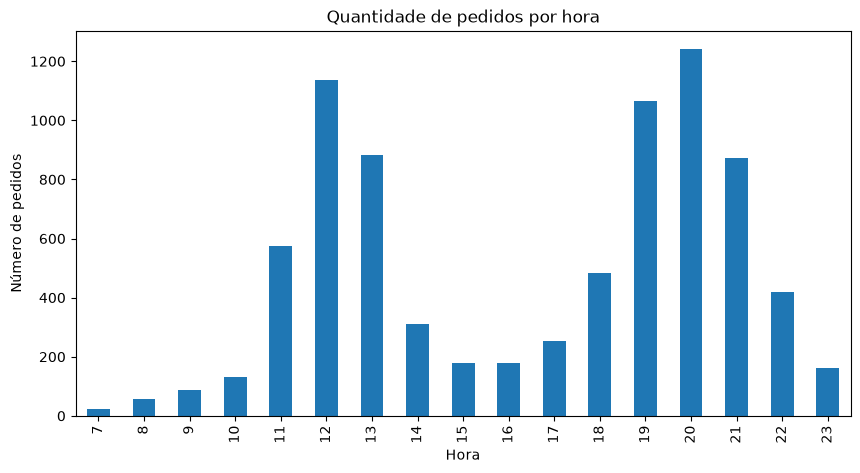

In [ ]:
pedidos_por_hora.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Quantidade de pedidos por hora")
plt.xlabel("Hora")
plt.ylabel("Número de pedidos")
plt.show()

Conclusão:
•	Almoço: o volume cresce fortemente às 11h e atinge o pico do período às 12h, com aproximadamente 1.130 pedidos.
•	Jantar: a demanda acelera a partir das 18h, ultrapassa 1.000 pedidos às 19h e chega ao maior pico do dia às 20h, com aproximadamente 1.240 pedidos.
•	Depois dos picos, há redução: 
o	após o almoço, o volume cai de 13h até 15h;
o	após o jantar, cai progressivamente entre 21h e 23h.
•	Os menores volumes aparecem no início da manhã, especialmente às 7h e 8h.
•	O intervalo entre 15h e 17h também apresenta demanda relativamente baixa.



Valores exatos:

In [ ]:
pedidos_por_hora

hora
7       22
8       56
9       86
10     132
11     574
12    1138
13     883
14     311
15     178
16     180
17     252
18     485
19    1066
20    1241
21     872
22     420
23     162
dtype: int64

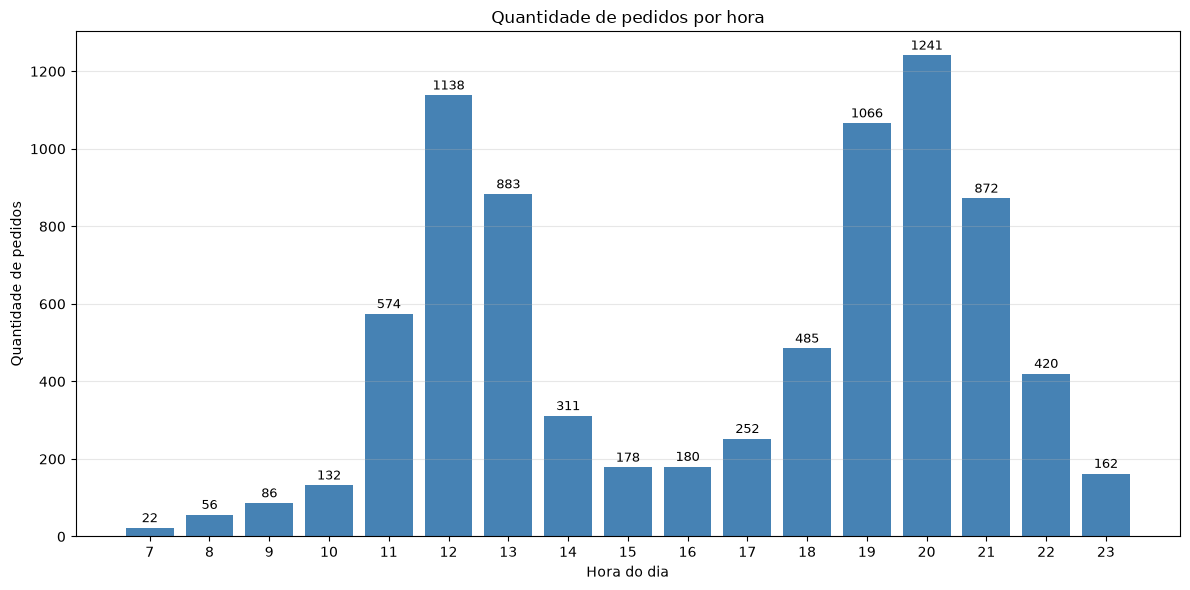

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    pedidos_por_hora.index,
    pedidos_por_hora.values,
    color="steelblue"
)

plt.title("Quantidade de pedidos por hora")
plt.xlabel("Hora do dia")
plt.ylabel("Quantidade de pedidos")

plt.xticks(pedidos_por_hora.index)
plt.grid(axis="y", alpha=0.3)

# Mostrar o valor em cima de cada barra
for hora, quantidade in pedidos_por_hora.items():
    plt.text(
        hora,
        quantidade + 15,
        str(quantidade),
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Horas com mais pedidos:

In [ ]:
pedidos_por_hora.sort_values(ascending=False).head()

hora
20    1241
12    1138
19    1066
13     883
21     872
dtype: int64

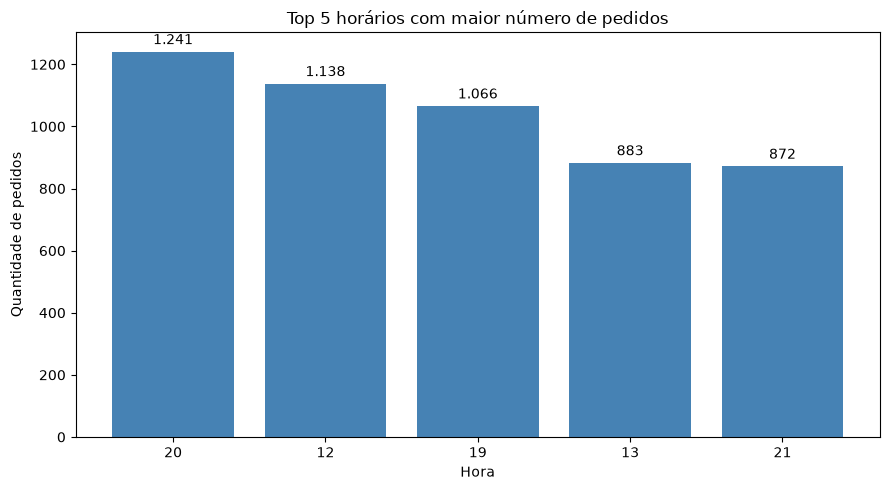

In [ ]:
import matplotlib.pyplot as plt

top5_horas = pedidos_por_hora.sort_values(ascending=False).head()

plt.figure(figsize=(9, 5))

barras = plt.bar(
    top5_horas.index.astype(str),
    top5_horas.values,
    color="steelblue"
)

plt.title("Top 5 horários com maior número de pedidos")
plt.xlabel("Hora")
plt.ylabel("Quantidade de pedidos")

# Valores em cima das barras
plt.bar_label(
    barras,
    labels=[f"{int(valor):,}".replace(",", ".") for valor in top5_horas.values],
    padding=3
)

plt.tight_layout()
plt.show()

Os pedidos se concentram principalmente nos períodos de almoço e jantar. O maior pico ocorre às 20h, com 1.241 pedidos, seguido por 12h, com 1.138, e 19h, com 1.066. Esses horários representam os principais períodos de pressão sobre a operação.

Ver os pedidos por mês

In [ ]:
pedidos_por_mes = (
    df.groupby("mes")
      .size()
      .sort_index()
)

pedidos_por_mes

mes
1     618
2     559
3     647
4     580
5     660
6     630
7     822
8     662
9     664
10    698
11    678
12    840
dtype: int64

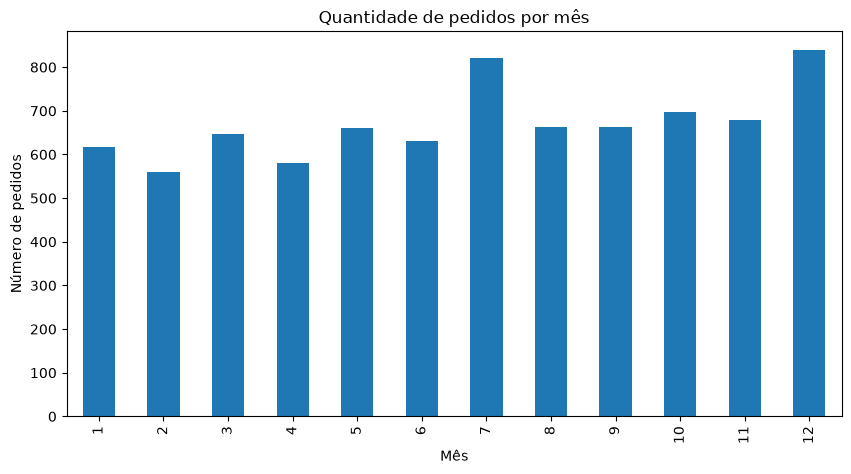

In [ ]:
pedidos_por_mes.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Quantidade de pedidos por mês")
plt.xlabel("Mês")
plt.ylabel("Número de pedidos")
plt.show()

Ver os Pedidos por dia da semana, será criada uma versão em português e contada:

In [ ]:
dias = {
    "Monday": "Segunda",
    "Tuesday": "Terça",
    "Wednesday": "Quarta",
    "Thursday": "Quinta",
    "Friday": "Sexta",
    "Saturday": "Sábado",
    "Sunday": "Domingo"
}

df["dia_semana_pt"] = df["dia_semana"].map(dias)

In [ ]:
ordem_dias = [
    "Segunda",
    "Terça",
    "Quarta",
    "Quinta",
    "Sexta",
    "Sábado",
    "Domingo"
]

pedidos_por_dia = (
    df["dia_semana_pt"]
    .value_counts()
    .reindex(ordem_dias)
)

pedidos_por_dia

dia_semana_pt
Segunda    1107
Terça      1064
Quarta     1020
Quinta     1049
Sexta      1379
Sábado     1365
Domingo    1074
Name: count, dtype: int64

Tempo de entrega

In [ ]:
operacao_por_hora = (
    df.groupby("hora")
      .agg(
          quantidade_pedidos=("pedido_id", "count"),
          tempo_medio_entrega=("tempo_entrega_min", "mean"),
          tempo_mediano_entrega=("tempo_entrega_min", "median")
      )
      .round(2)
)

operacao_por_hora

,quantidade_pedidos,tempo_medio_entrega,tempo_mediano_entrega
hora,,,
7,22,31.05,31.5
8,56,51.57,34.5
9,86,44.00,33.0
10,132,47.89,32.5
11,574,33.02,31.0
12,1138,40.88,38.0
13,883,40.00,37.0
14,311,32.48,31.0
15,178,37.29,31.5


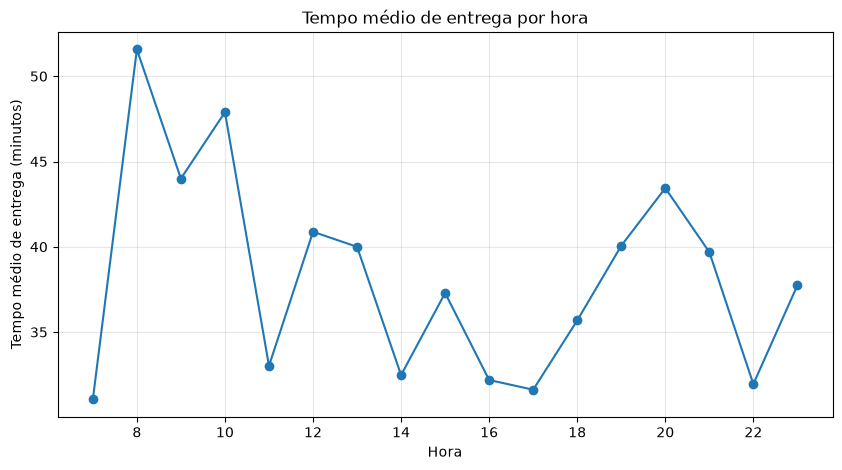

In [ ]:
operacao_por_hora["tempo_medio_entrega"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Tempo médio de entrega por hora")
plt.xlabel("Hora")
plt.ylabel("Tempo médio de entrega (minutos)")
plt.grid(alpha=0.3)
plt.show()

•	8h: ~52 minutos
•	10h: ~48 minutos
•	9h: ~44 minutos
•	20h: ~43–44 minutos
•	12h: ~41 minutos
Já os menores tempos aparecem aproximadamente em:
•	7h: ~31 minutos
•	17h: ~32 minutos
•	22h: ~32 minutos
•	14h: ~33 minutos
Cruzando com o volume de pedidos
Dos resultados anteriores, sabemos que:
•	20h: 1.241 pedidos, maior volume
•	12h: 1.138
•	19h: 1.066
•	13h: 883
•	21h: 872
É interessante que 20h combina volume muito alto com tempo médio relativamente elevado, enquanto os tempos visualmente mais altos, como 8h e 10h, acontecem em horários com menos pedidos.
Isso sugere que o volume de pedidos sozinho provavelmente não explica toda a variação no tempo de entrega.


Valores exatos

In [ ]:
operacao_por_hora.sort_values(
    "tempo_medio_entrega",
    ascending=False
)

,quantidade_pedidos,tempo_medio_entrega,tempo_mediano_entrega
hora,,,
8,56,51.57,34.5
10,132,47.89,32.5
9,86,44.00,33.0
20,1241,43.44,37.0
12,1138,40.88,38.0
19,1066,40.06,37.0
13,883,40.00,37.0
21,872,39.69,36.0
23,162,37.74,31.0


Possíveis fatores associados ao tempo de entrega:

In [ ]:
df.groupby("chuva")["tempo_entrega_min"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
chuva,,,
False,5691,36.06,33.0
True,2367,45.56,42.0


A diferença da média é:

45,56 − 36,06 = 9,50 minutos

Ou seja, na sua amostra, pedidos feitos quando chuva=True apresentam tempo médio de entrega 9,5 minutos maior.

Qual a conclusão?

In [ ]:
aumento_percentual = (45.56 - 36.06) / 36.06 * 100
print(round(aumento_percentual, 2))

26.34


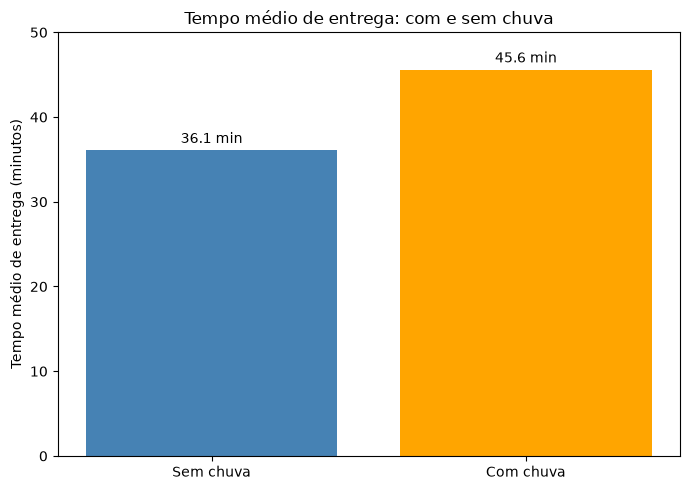

In [ ]:
tempo_chuva = (
    df.groupby("chuva")["tempo_entrega_min"]
      .mean()
)

plt.figure(figsize=(7, 5))

barras = plt.bar(
    ["Sem chuva", "Com chuva"],
    tempo_chuva.values,
    color=["steelblue", "orange"]
)

plt.title("Tempo médio de entrega: com e sem chuva")
plt.ylabel("Tempo médio de entrega (minutos)")

plt.bar_label(
    barras,
    labels=[f"{v:.1f} min" for v in tempo_chuva.values],
    padding=3
)

plt.ylim(0, 50)
plt.tight_layout()
plt.show()


Por distância:

In [ ]:
df[
    ["distancia_km", "tempo_entrega_min"]
].corr()


,distancia_km,tempo_entrega_min
distancia_km,1.000000,0.032655
tempo_entrega_min,0.032655,1.000000


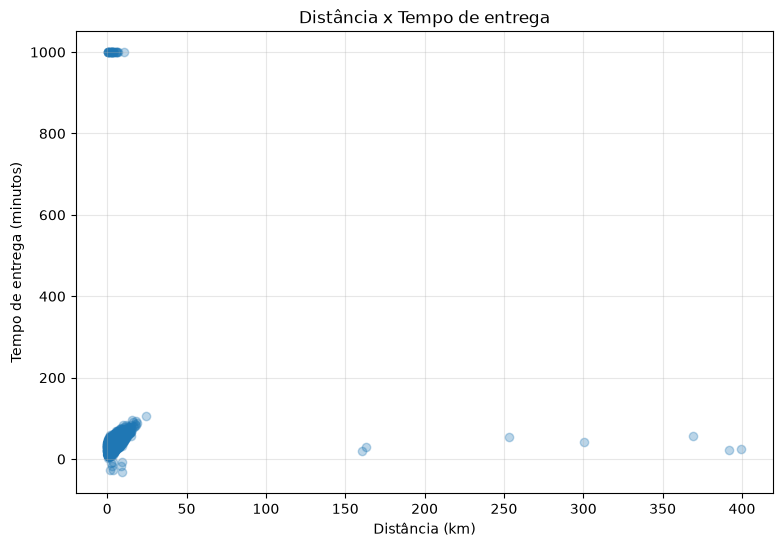

In [ ]:
import matplotlib.pyplot as plt

dados = df.dropna(subset=["distancia_km", "tempo_entrega_min"])

plt.figure(figsize=(9, 6))

plt.scatter(
    dados["distancia_km"],
    dados["tempo_entrega_min"],
    alpha=0.3
)

plt.title("Distância x Tempo de entrega")
plt.xlabel("Distância (km)")
plt.ylabel("Tempo de entrega (minutos)")
plt.grid(alpha=0.3)

plt.show()

Por cidade:

In [ ]:
df.groupby("cidade")["tempo_entrega_min"].agg(
    ["count", "mean", "median"]
).round(2).sort_values("mean", ascending=False)

,count,mean,median
cidade,,,
São Paulo,115,43.42,34.0
Belo Horizonte,1418,39.80,36.0
São Paulo,3579,39.08,35.0
Rio de Janeiro,2064,39.05,35.0
BH,79,36.53,36.0
sao paulo,114,36.07,35.0
SP,123,36.07,38.0
RJ,103,35.84,35.0
SÃO PAULO,124,35.31,35.0


Não há uma padronização nas cidades, vou criar um padrão.

In [ ]:
mapa_cidades = {
    "São Paulo": "São Paulo",
    "Sao Paulo": "São Paulo",
    "sao paulo": "São Paulo",
    "SÃO PAULO": "São Paulo",
    "SP": "São Paulo",

    "Belo Horizonte": "Belo Horizonte",
    "BH": "Belo Horizonte",

    "Rio de Janeiro": "Rio de Janeiro",
    "rio de janeiro": "Rio de Janeiro",
    "RJ": "Rio de Janeiro"
}

df["cidade_limpa"] = df["cidade"].replace(mapa_cidades)

In [ ]:
Verificando ação.

In [ ]:
df["cidade_limpa"].value_counts(dropna=False)

cidade_limpa
São Paulo         3940
Rio de Janeiro    2270
Belo Horizonte    1497
São Paulo          115
Rio                101
belo horizonte      72
B. Horizonte        63
Name: count, dtype: int64

Melhorando a padronização:

In [ ]:
import unicodedata

def normalizar_texto(texto):
    if texto is None:
        return texto
    
    texto = str(texto).strip().lower()
    
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        caractere
        for caractere in texto
        if not unicodedata.combining(caractere)
    )
    
    return texto

In [ ]:
df["cidade_chave"] = df["cidade"].apply(normalizar_texto)

df["cidade_chave"].value_counts()

cidade_chave
sao paulo         3932
rio de janeiro    2167
belo horizonte    1490
sp                 123
rj                 103
rio                101
bh                  79
b. horizonte        63
Name: count, dtype: int64

In [ ]:
mapa_cidades = {
    "São Paulo": "São Paulo",
    "Sao Paulo": "São Paulo",
    "sao paulo": "São Paulo",
    "SÃO PAULO": "São Paulo",
    "SP": "São Paulo",

    "Belo Horizonte": "Belo Horizonte",
    "BH": "Belo Horizonte",

    "Rio de Janeiro": "Rio de Janeiro",
    "rio de janeiro": "Rio de Janeiro",
    "RJ": "Rio de Janeiro"
}

df["cidade_limpa"] = df["cidade"].replace(mapa_cidades)

In [ ]:
df["cidade_limpa"].value_counts(dropna=False)

cidade_limpa
São Paulo         3940
Rio de Janeiro    2270
Belo Horizonte    1497
São Paulo          115
Rio                101
belo horizonte      72
B. Horizonte        63
Name: count, dtype: int64

Gerando cidade chave

In [ ]:
mapa_cidades = {
    "sao paulo": "São Paulo",
    "sp": "São Paulo",

    "rio de janeiro": "Rio de Janeiro",
    "rj": "Rio de Janeiro",
    "rio": "Rio de Janeiro",

    "belo horizonte": "Belo Horizonte",
    "bh": "Belo Horizonte",
    "b. horizonte": "Belo Horizonte"
}

df["cidade_limpa"] = df["cidade_chave"].map(mapa_cidades)

df["cidade_limpa"].value_counts(dropna=False)

cidade_limpa
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

In [ ]:
print(df["cidade_limpa"].value_counts(dropna=False))
print()
print("Número de cidades:", df["cidade_limpa"].nunique())
print("Valores não mapeados:", df["cidade_limpa"].isna().sum())
print("Total de pedidos:", df["cidade_limpa"].notna().sum())


cidade_limpa
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

Número de cidades: 3
Valores não mapeados: 0
Total de pedidos: 8058


In [ ]:
tempo_por_cidade = (
    df.groupby("cidade_limpa")["tempo_entrega_min"]
      .agg(["count", "mean", "median"])
      .round(2)
      .sort_values("mean", ascending=False)
)

tempo_por_cidade

,count,mean,median
cidade_limpa,,,
Belo Horizonte,1632,39.22,36.0
São Paulo,4055,38.91,35.0
Rio de Janeiro,2371,38.49,35.0


cidade × chuva

In [ ]:
cidade_chuva = (
    df.groupby(["cidade_limpa", "chuva"])["tempo_entrega_min"]
      .agg(
          pedidos="count",
          tempo_medio="mean",
          mediana="median"
      )
      .round(2)
)

cidade_chuva


pedidos  tempo_medio  mediana
cidade_limpa   chuva                               
Belo Horizonte False     1128        36.17     33.0
               True       504        46.04     42.0
Rio de Janeiro False     1724        36.06     33.0
               True       647        44.98     41.0
São Paulo      False     2839        36.01     32.0
               True      1216        45.68     42.0

In [ ]:
comparacao_chuva = (
    df.groupby(["cidade_limpa", "chuva"])["tempo_entrega_min"]
      .mean()
      .unstack()
      .round(2)
)

comparacao_chuva.columns = ["Sem chuva", "Com chuva"]

comparacao_chuva["Diferença (min)"] = (
    comparacao_chuva["Com chuva"] -
    comparacao_chuva["Sem chuva"]
).round(2)

comparacao_chuva

,Sem chuva,Com chuva,Diferença (min)
cidade_limpa,,,
Belo Horizonte,36.17,46.04,9.87
Rio de Janeiro,36.06,44.98,8.92
São Paulo,36.01,45.68,9.67


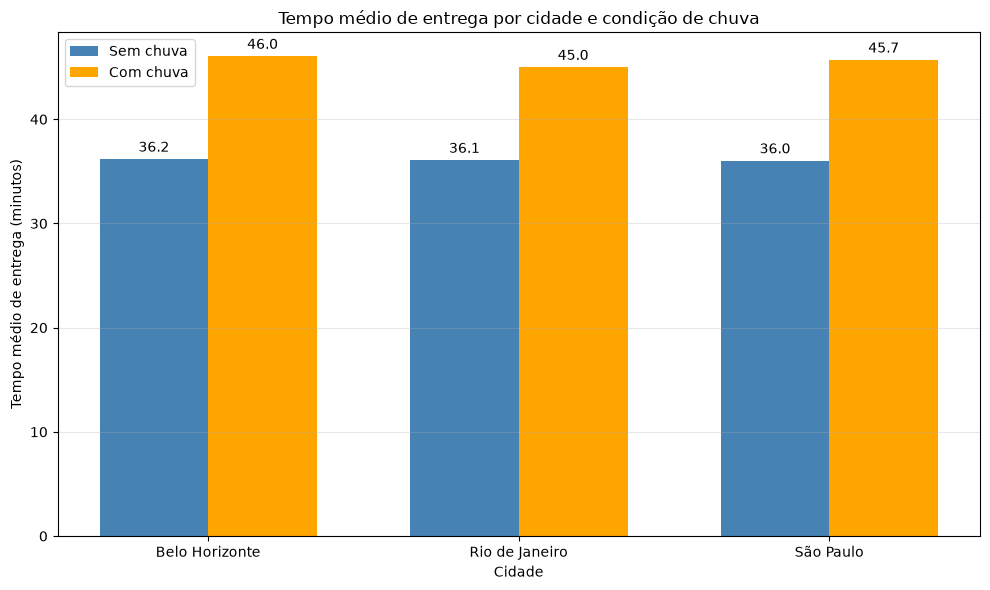

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cidades = comparacao_chuva.index

sem_chuva = comparacao_chuva["Sem chuva"]
com_chuva = comparacao_chuva["Com chuva"]

x = np.arange(len(cidades))
largura = 0.35

plt.figure(figsize=(10, 6))

barra1 = plt.bar(
    x - largura/2,
    sem_chuva,
    largura,
    label="Sem chuva",
    color="steelblue"
)

barra2 = plt.bar(
    x + largura/2,
    com_chuva,
    largura,
    label="Com chuva",
    color="orange"
)

plt.bar_label(barra1, fmt="%.1f", padding=3)
plt.bar_label(barra2, fmt="%.1f", padding=3)

plt.title("Tempo médio de entrega por cidade e condição de chuva")
plt.xlabel("Cidade")
plt.ylabel("Tempo médio de entrega (minutos)")

plt.xticks(x, cidades)
plt.legend()

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

A chuva apresenta associação consistente com maiores tempos de entrega nas três cidades analisadas. Sem chuva, o tempo médio permanece próximo de 36 minutos em todas as cidades. Em condições de chuva, a média sobe para 46,04 minutos em Belo Horizonte, 45,68 minutos em São Paulo e 44,98 minutos no Rio de Janeiro, representando aumentos de 9,87, 9,67 e 8,92 minutos, respectivamente. As diferenças entre cidades são relativamente pequenas quando comparadas à diferença observada entre pedidos com e sem chuva.

Avaliação dos clientes, verificando se chuva e tempo de entrega também estão associados a notas mais baixas.

1.	A chuva está associada a avaliações menores?
2.	Entregas mais demoradas estão associadas a avaliações menores?
Como avaliação tem 1.342 valores ausentes, não serão preenchidas essas notas artificialmente. As análises de avaliação usarão apenas os pedidos que realmente têm nota.


In [ ]:
print("Avaliações preenchidas:", df["avaliacao"].notna().sum())
print("Avaliações ausentes:", df["avaliacao"].isna().sum())

df["avaliacao"].describe()

Avaliações preenchidas: 6716
Avaliações ausentes: 1342


count    6716.000000
mean        4.348868
std         0.685299
min         1.000000
25%         4.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: avaliacao, dtype: float64

In [ ]:
df["avaliacao"].value_counts().sort_index()

avaliacao
1.0       1
2.0      40
3.0     688
4.0    2873
5.0    3114
Name: count, dtype: int64

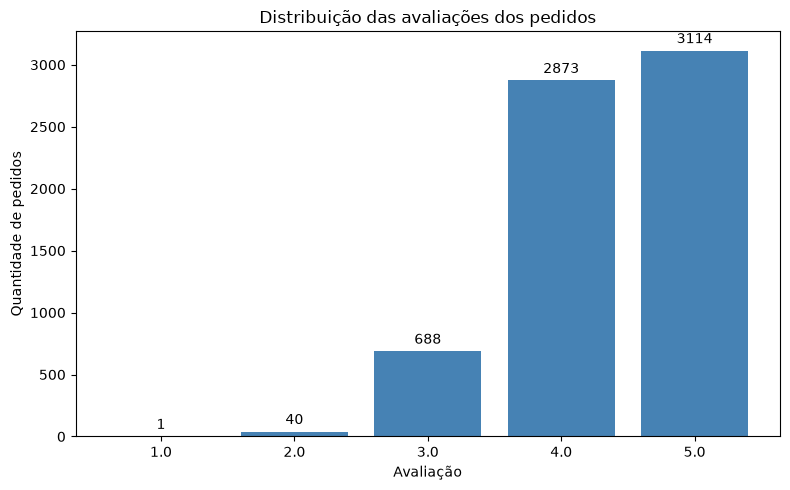

In [ ]:
import matplotlib.pyplot as plt

avaliacoes = df["avaliacao"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    avaliacoes.index.astype(str),
    avaliacoes.values,
    color="steelblue"
)

plt.bar_label(barras, padding=3)

plt.title("Distribuição das avaliações dos pedidos")
plt.xlabel("Avaliação")
plt.ylabel("Quantidade de pedidos")

plt.tight_layout()
plt.show()

In [ ]:
avaliacao_chuva = (
    df.groupby("chuva")["avaliacao"]
      .agg(["count", "mean", "median"])
      .round(2)
)

avaliacao_chuva

,count,mean,median
chuva,,,
False,4746,4.39,4.0
True,1970,4.25,4.0


In [ ]:
df[
    ["tempo_entrega_min", "avaliacao"]
].corr()

,tempo_entrega_min,avaliacao
tempo_entrega_min,1.000000,-0.055333
avaliacao,-0.055333,1.000000


In [ ]:
tempo_por_avaliacao = (
    df.groupby("avaliacao")["tempo_entrega_min"]
      .agg(["count", "mean", "median"])
      .round(2)
)

tempo_por_avaliacao

,count,mean,median
avaliacao,,,
1.0,1,37.00,37.0
2.0,40,58.10,59.0
3.0,688,45.18,42.0
4.0,2873,40.59,37.0
5.0,3114,36.29,33.0


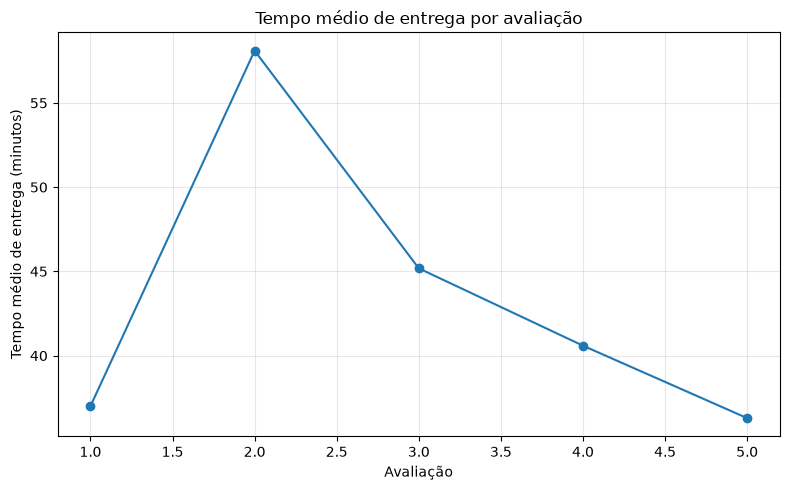

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    tempo_por_avaliacao.index,
    tempo_por_avaliacao["mean"],
    marker="o"
)

plt.title("Tempo médio de entrega por avaliação")
plt.xlabel("Avaliação")
plt.ylabel("Tempo médio de entrega (minutos)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Variável de avaliação baixa:

In [ ]:
df["avaliacao_baixa"] = df["avaliacao"] <= 2

In [ ]:
df["avaliacao_baixa"] = df["avaliacao"].apply(
    lambda x: True if x <= 2
    else False if x > 2
    else None
)

Somente pedidos avaliados

In [ ]:
df_avaliados = df.dropna(
    subset=["avaliacao", "tempo_entrega_min", "chuva"]
).copy()

df_avaliados["avaliacao_baixa"] = (
    df_avaliados["avaliacao"] <= 2
)

print("Pedidos avaliados:", len(df_avaliados))
print(
    "Percentual de avaliações baixas:",
    round(df_avaliados["avaliacao_baixa"].mean() * 100, 2),
    "%"
)

Pedidos avaliados: 6716
Percentual de avaliações baixas: 0.61 %


In [ ]:
chuva_tempo_avaliados = (
    df_avaliados.groupby("chuva")["tempo_entrega_min"]
    .agg(
        pedidos="count",
        tempo_medio="mean",
        mediana="median"
    )
    .round(2)
)

chuva_tempo_avaliados

,pedidos,tempo_medio,mediana
chuva,,,
False,4746,36.20,33.0
True,1970,46.33,42.0


In [ ]:
tempo_avaliacao_baixa = (
    df_avaliados.groupby("avaliacao_baixa")["tempo_entrega_min"]
    .agg(
        pedidos="count",
        tempo_medio="mean",
        mediana="median"
    )
    .round(2)
)

tempo_avaliacao_baixa.index = [
    "Avaliação acima de 2",
    "Avaliação baixa (1 ou 2)"
]

tempo_avaliacao_baixa


,pedidos,tempo_medio,mediana
Avaliação acima de 2,6675,39.06,35.0
Avaliação baixa (1 ou 2),41,57.59,59.0


In [ ]:
faixas = [0, 30, 40, 50, 60, float("inf")]

rotulos = [
    "Até 30 min",
    "31–40 min",
    "41–50 min",
    "51–60 min",
    "Acima de 60 min"
]

df_avaliados["faixa_tempo"] = pd.cut(
    df_avaliados["tempo_entrega_min"],
    bins=faixas,
    labels=rotulos,
    include_lowest=True,
    right=True
)

avaliacao_por_tempo = (
    df_avaliados.groupby(
        "faixa_tempo",
        observed=False
    )
    .agg(
        pedidos=("pedido_id", "count"),
        tempo_medio=("tempo_entrega_min", "mean"),
        nota_media=("avaliacao", "mean"),
        taxa_avaliacao_baixa=("avaliacao_baixa", "mean")
    )
)

avaliacao_por_tempo["taxa_avaliacao_baixa"] *= 100

avaliacao_por_tempo.round(2)

,pedidos,tempo_medio,nota_media,taxa_avaliacao_baixa
faixa_tempo,,,,
Até 30 min,2177,24.14,4.49,0.05
31–40 min,2403,35.37,4.45,0.21
41–50 min,1439,44.90,4.22,0.35
51–60 min,524,54.44,3.92,2.67
Acima de 60 min,165,197.25,3.59,9.70


Gráfico da taxa de avaliações baixas

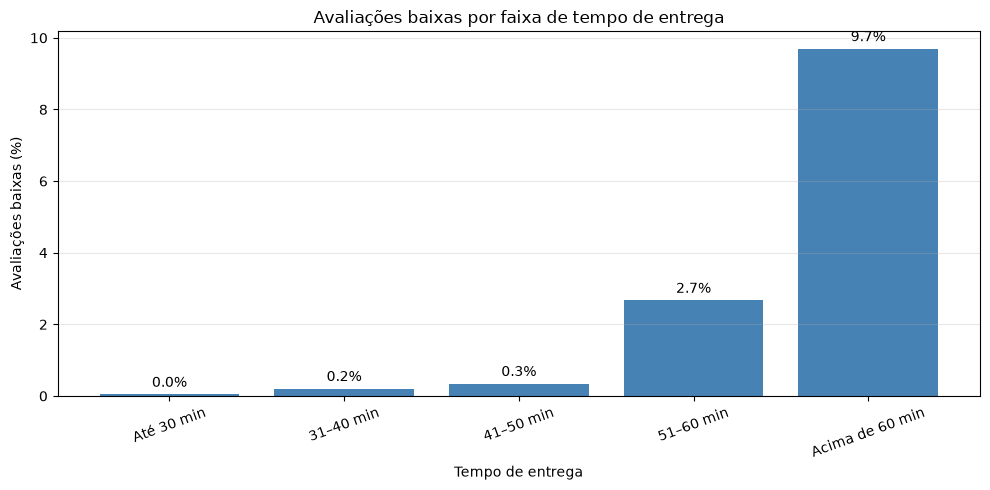

In [ ]:
import matplotlib.pyplot as plt

taxa_baixa = avaliacao_por_tempo["taxa_avaliacao_baixa"]

plt.figure(figsize=(10, 5))

barras = plt.bar(
    taxa_baixa.index.astype(str),
    taxa_baixa.values,
    color="steelblue"
)

plt.bar_label(
    barras,
    labels=[f"{valor:.1f}%" for valor in taxa_baixa.values],
    padding=3
)

plt.title("Avaliações baixas por faixa de tempo de entrega")
plt.xlabel("Tempo de entrega")
plt.ylabel("Avaliações baixas (%)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Chuva → avaliação baixa

In [ ]:
chuva_avaliacao = (
    df_avaliados.groupby("chuva")
    .agg(
        pedidos_avaliados=("pedido_id", "count"),
        nota_media=("avaliacao", "mean"),
        taxa_avaliacao_baixa=("avaliacao_baixa", "mean")
    )
)

chuva_avaliacao["taxa_avaliacao_baixa"] *= 100

chuva_avaliacao.index = ["Sem chuva", "Com chuva"]

chuva_avaliacao.round(2)

,pedidos_avaliados,nota_media,taxa_avaliacao_baixa
Sem chuva,4746,4.39,0.46
Com chuva,1970,4.25,0.96


Cruzar chuva e tempo

In [ ]:
chuva_tempo_avaliacao = (
    df_avaliados.groupby(
        ["chuva", "faixa_tempo"],
        observed=False
    )
    .agg(
        pedidos=("pedido_id", "count"),
        nota_media=("avaliacao", "mean"),
        taxa_avaliacao_baixa=("avaliacao_baixa", "mean")
    )
    .reset_index()
)

chuva_tempo_avaliacao["taxa_avaliacao_baixa"] *= 100

chuva_tempo_avaliacao.round(2)

,chuva,faixa_tempo,pedidos,nota_media,taxa_avaliacao_baixa
0,False,Até 30 min,1956,4.48,0.05
1,False,31–40 min,1733,4.46,0.23
2,False,41–50 min,780,4.21,0.64
3,False,51–60 min,205,3.93,2.93
4,False,Acima de 60 min,65,3.72,9.23
5,True,Até 30 min,221,4.57,0.00
6,True,31–40 min,670,4.43,0.15
7,True,41–50 min,659,4.22,0.00
8,True,51–60 min,319,3.91,2.51
9,True,Acima de 60 min,100,3.51,10.00


In [ ]:
tabela_cruzada = (
    chuva_tempo_avaliacao.pivot(
        index="faixa_tempo",
        columns="chuva",
        values="taxa_avaliacao_baixa"
    )
    .rename(
        columns={
            False: "Sem chuva",
            True: "Com chuva"
        }
    )
    .round(2)
)

tabela_cruzada

chuva,Sem chuva,Com chuva
faixa_tempo,,
Até 30 min,0.05,0.00
31–40 min,0.23,0.15
41–50 min,0.64,0.00
51–60 min,2.93,2.51
Acima de 60 min,9.23,10.00


Correlação entre tempo de entrega e avaliação

In [ ]:
correlacao = df[
    ["tempo_entrega_min", "avaliacao"]
].corr()

correlacao

,tempo_entrega_min,avaliacao
tempo_entrega_min,1.000000,-0.055333
avaliacao,-0.055333,1.000000


In [ ]:
corr_tempo_avaliacao = df[
    "tempo_entrega_min"
].corr(df["avaliacao"])

print(f"Correlação: {corr_tempo_avaliacao:.3f}")

Correlação: -0.055


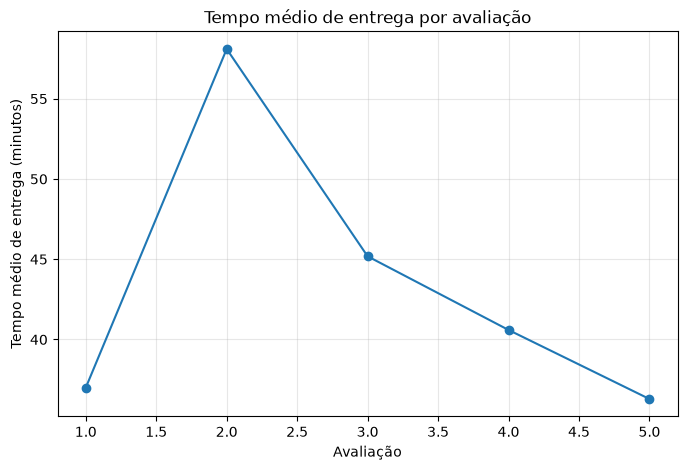

In [ ]:
tempo_por_nota = (
    df.groupby("avaliacao")["tempo_entrega_min"]
      .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    tempo_por_nota.index,
    tempo_por_nota.values,
    marker="o"
)

plt.title("Tempo médio de entrega por avaliação")
plt.xlabel("Avaliação")
plt.ylabel("Tempo médio de entrega (minutos)")
plt.grid(alpha=0.3)

plt.show()

Quantidade de observações e a mediana de cada nota:

In [ ]:
resumo_avaliacoes = (
    df.groupby("avaliacao")["tempo_entrega_min"]
      .agg(
          quantidade="count",
          media="mean",
          mediana="median",
          desvio_padrao="std"
      )
      .round(2)
)

resumo_avaliacoes

,quantidade,media,mediana,desvio_padrao
avaliacao,,,,
1.0,1,37.00,37.0,NaN
2.0,40,58.10,59.0,14.91
3.0,688,45.18,42.0,53.39
4.0,2873,40.59,37.0,60.48
5.0,3114,36.29,33.0,55.46


In [ ]:
correlacao = df["tempo_entrega_min"].corr(df["avaliacao"])

print(f"Correlação entre tempo e avaliação: {correlacao:.3f}")

Correlação entre tempo e avaliação: -0.055


In [ ]:
resumo_por_nota = (
    df.dropna(subset=["avaliacao"])
      .groupby("avaliacao")["tempo_entrega_min"]
      .agg(
          quantidade_pedidos="count",
          tempo_medio="mean",
          tempo_mediano="median"
      )
      .round(2)
)

resumo_por_nota

,quantidade_pedidos,tempo_medio,tempo_mediano
avaliacao,,,
1.0,1,37.00,37.0
2.0,40,58.10,59.0
3.0,688,45.18,42.0
4.0,2873,40.59,37.0
5.0,3114,36.29,33.0


In [ ]:
resumo_por_nota["percentual"] = (
    resumo_por_nota["quantidade_pedidos"]
    / resumo_por_nota["quantidade_pedidos"].sum()
    * 100
).round(2)

resumo_por_nota

,quantidade_pedidos,tempo_medio,tempo_mediano,percentual
avaliacao,,,,
1.0,1,37.00,37.0,0.01
2.0,40,58.10,59.0,0.60
3.0,688,45.18,42.0,10.24
4.0,2873,40.59,37.0,42.78
5.0,3114,36.29,33.0,46.37


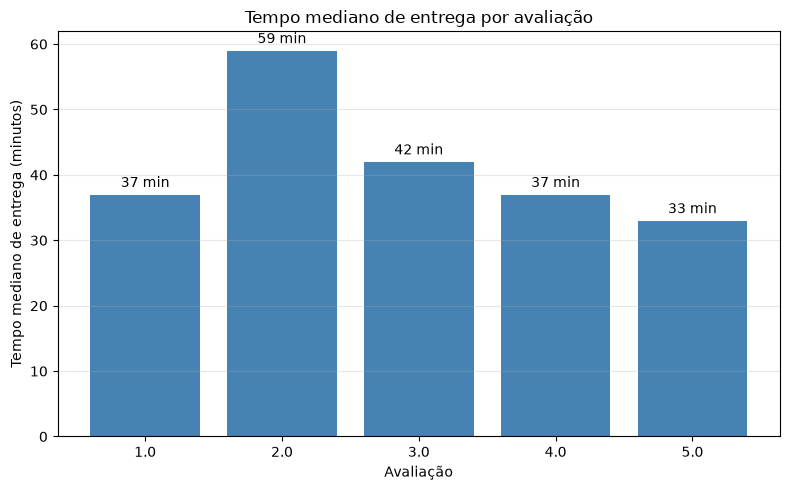

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

barras = plt.bar(
    resumo_por_nota.index.astype(str),
    resumo_por_nota["tempo_mediano"],
    color="steelblue"
)

plt.bar_label(
    barras,
    labels=[
        f"{valor:.0f} min"
        for valor in resumo_por_nota["tempo_mediano"]
    ],
    padding=3
)

plt.title("Tempo mediano de entrega por avaliação")
plt.xlabel("Avaliação")
plt.ylabel("Tempo mediano de entrega (minutos)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
resumo_por_nota = (
    df.dropna(subset=["avaliacao"])
      .groupby("avaliacao")
      .agg(
          quantidade_pedidos=("pedido_id", "count"),
          tempo_medio=("tempo_entrega_min", "mean"),
          tempo_mediano=("tempo_entrega_min", "median")
      )
      .round(2)
)

resumo_por_nota["percentual"] = (
    resumo_por_nota["quantidade_pedidos"]
    / resumo_por_nota["quantidade_pedidos"].sum()
    * 100
).round(2)

resumo_por_nota

,quantidade_pedidos,tempo_medio,tempo_mediano,percentual
avaliacao,,,,
1.0,1,37.00,37.0,0.01
2.0,40,58.10,59.0,0.60
3.0,688,45.18,42.0,10.24
4.0,2873,40.59,37.0,42.78
5.0,3114,36.29,33.0,46.37


Os resultados indicam associação entre o tempo de entrega e a satisfação dos clientes. Pedidos avaliados com nota 2 apresentaram mediana de 59 minutos de entrega, enquanto pedidos com nota 5 apresentaram mediana de 33 minutos. Entre as notas 2 e 5, observa-se queda progressiva tanto da média quanto da mediana do tempo de entrega à medida que a avaliação aumenta. A nota 1 foi desconsiderada na interpretação comparativa por conter apenas uma observação.

In [ ]:
corr_tempo_avaliacao = df[
    "tempo_entrega_min"
].corr(df["avaliacao"])

print(
    f"Correlação entre tempo de entrega e avaliação: "
    f"{corr_tempo_avaliacao:.3f}"
)

Correlação entre tempo de entrega e avaliação: -0.055


A correlação linear entre tempo de entrega e avaliação foi negativa, porém muito fraca (r = -0,055), indicando baixa associação linear global entre as duas variáveis. Entretanto, a análise agrupada por nota revela que, entre as avaliações 2 e 5, avaliações mais altas estão associadas a menores tempos médios e medianos de entrega. A nota 1 não foi considerada representativa, pois contém apenas uma observação.

In [ ]:
# Selecionar somente pedidos com avaliação preenchida
df_avaliados = df.dropna(
    subset=["avaliacao", "tempo_entrega_min"]
).copy()

# Identificar avaliações baixas
df_avaliados["avaliacao_baixa"] = (
    df_avaliados["avaliacao"] <= 2
)

# Criar faixas de tempo
faixas = [0, 30, 40, 50, 60, float("inf")]

rotulos = [
    "Até 30 min",
    "31-40 min",
    "41-50 min",
    "51-60 min",
    "Acima de 60 min"
]

df_avaliados["faixa_tempo"] = pd.cut(
    df_avaliados["tempo_entrega_min"],
    bins=faixas,
    labels=rotulos,
    include_lowest=True,
    right=True
)

In [ ]:
avaliacoes_por_faixa = (
    df_avaliados
    .groupby("faixa_tempo", observed=False)
    .agg(
        pedidos_avaliados=("pedido_id", "count"),
        avaliacoes_baixas=("avaliacao_baixa", "sum"),
        nota_media=("avaliacao", "mean")
    )
)

avaliacoes_por_faixa["taxa_avaliacoes_baixas"] = (
    avaliacoes_por_faixa["avaliacoes_baixas"]
    / avaliacoes_por_faixa["pedidos_avaliados"]
    * 100
)

avaliacoes_por_faixa.round(2)


,pedidos_avaliados,avaliacoes_baixas,nota_media,taxa_avaliacoes_baixas
faixa_tempo,,,,
Até 30 min,2177,1,4.49,0.05
31-40 min,2403,5,4.45,0.21
41-50 min,1439,5,4.22,0.35
51-60 min,524,14,3.92,2.67
Acima de 60 min,165,16,3.59,9.70


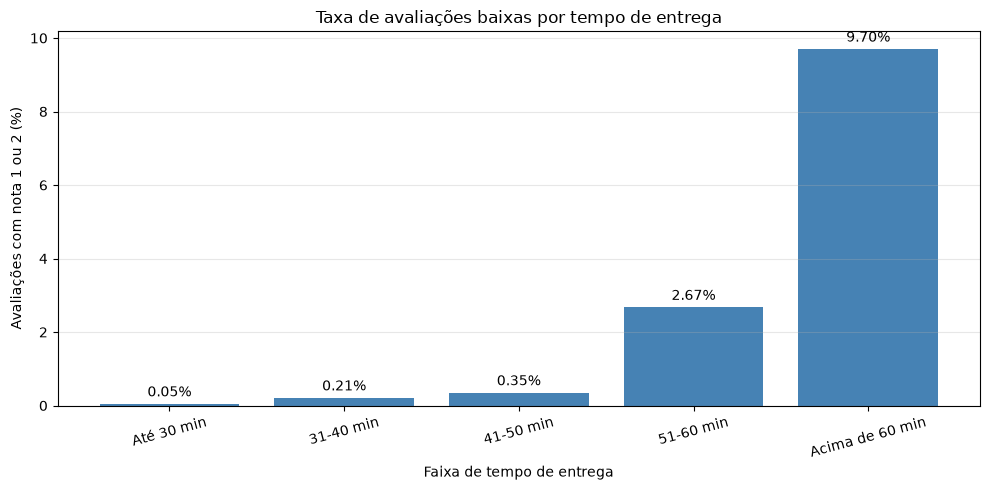

In [ ]:
import matplotlib.pyplot as plt

taxas = avaliacoes_por_faixa["taxa_avaliacoes_baixas"]

plt.figure(figsize=(10, 5))

barras = plt.bar(
    taxas.index.astype(str),
    taxas.values,
    color="steelblue"
)

plt.bar_label(
    barras,
    labels=[f"{valor:.2f}%" for valor in taxas.values],
    padding=3
)

plt.title("Taxa de avaliações baixas por tempo de entrega")
plt.xlabel("Faixa de tempo de entrega")
plt.ylabel("Avaliações com nota 1 ou 2 (%)")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Embora a correlação linear entre tempo de entrega e avaliação seja muito fraca (r = -0,055), a análise por faixas revela um padrão relevante. A taxa de avaliações baixas permanece inferior a 0,4% nas entregas de até 50 minutos, sobe para 2,67% entre 51 e 60 minutos e alcança 9,70% nas entregas acima de 60 minutos. Os resultados sugerem que entregas superiores a 50 minutos estão associadas a um aumento expressivo na frequência de avaliações baixas.

In [ ]:
avaliacoes_por_faixa[
    [
        "pedidos_avaliados",
        "avaliacoes_baixas",
        "taxa_avaliacoes_baixas"
    ]
].round(2)

,pedidos_avaliados,avaliacoes_baixas,taxa_avaliacoes_baixas
faixa_tempo,,,
Até 30 min,2177,1,0.05
31-40 min,2403,5,0.21
41-50 min,1439,5,0.35
51-60 min,524,14,2.67
Acima de 60 min,165,16,9.70


In [ ]:
df_avaliados[
    df_avaliados["faixa_tempo"].isna()
][
    ["pedido_id", "tempo_entrega_min", "avaliacao"]
]

,pedido_id,tempo_entrega_min,avaliacao
1896,501896,-7,3.0
2262,502262,-8,4.0
2661,502661,-33,4.0
2701,502701,-10,4.0
2799,502799,-26,5.0
4105,504105,-17,5.0
5960,505960,-28,4.0
6286,506286,-18,4.0


Resultados validados
Até 30 min: 1 avaliação baixa em 2.177 pedidos, 0,05%
31–40 min: 5 em 2.403, 0,21%
41–50 min: 5 em 1.439, 0,35%
51–60 min: 14 em 524, 2,67%
Acima de 60 min: 16 em 165, 9,70%

As quantidades totalizam 6.708 pedidos avaliados e 41 avaliações baixas. A diferença para os 6.716 pedidos com avaliação indica que 8 registros ficaram fora dessas faixas, provavelmente por apresentarem tempo igual a zero, negativo ou ausente após algum tratamento. 

O risco de uma avaliação baixa cresce de forma acentuada após 50 minutos:

51–60 minutos: taxa aproximadamente 7,6 vezes maior que na faixa de 41–50 minutos.
Acima de 60 minutos: taxa aproximadamente 27,7 vezes maior que na faixa de 41–50 minutos.
Acima de 60 minutos, aproximadamente 1 em cada 10 pedidos avaliados recebeu nota 1 ou 2.

Além disso, 30 das 41 avaliações baixas, cerca de 73,2%, estão em entregas superiores a 50 minutos, apesar de essas faixas reunirem somente 689 dos 6.708 pedidos avaliados, aproximadamente 10,3%.

Embora a correlação linear entre tempo de entrega e avaliação seja muito fraca (r = -0,055), a análise por faixas evidencia um efeito de limiar. As avaliações baixas permanecem abaixo de 0,4% nas entregas de até 50 minutos, sobem para 2,67% entre 51 e 60 minutos e alcançam 9,70% acima de 60 minutos. Portanto, entregas superiores a 50 minutos representam o principal ponto de risco para a satisfação dos clientes, especialmente quando ultrapassam uma hora.

Operacionalmente, 50 minutos pode ser tratado como um limite de alerta, enquanto entregas próximas de 60 minutos devem receber priorização para evitar uma deterioração acentuada da experiência do cliente.